In [1]:
!pip install shap



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import shap
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
rf_model = joblib.load("../models/crop_recommendation_rf.pkl")
scaler = joblib.load("../models/scaler.pkl")
label_encoder = joblib.load("../models/label_encoder.pkl")

In [4]:
df = pd.read_csv("../data/processed/crop_recommendation_cleaned.csv")

X = df.drop(columns=["label"])
X.head()

,n,p,k,temperature,humidity,soil_ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340


In [5]:
X_scaled = scaler.transform(X)

In [6]:
explainer = shap.TreeExplainer(rf_model)

In [7]:
X_sample = X_scaled[:100]

In [8]:
shap_values = explainer.shap_values(X_sample)

IndexError: index 20 is out of bounds for axis 1 with size 7

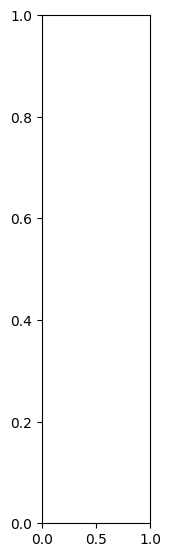

In [9]:
shap.summary_plot(shap_values, X_sample, feature_names=X.columns)

In [10]:
shap.summary_plot(shap_values[0], X_sample, feature_names=X.columns)


AssertionError: The shape of the shap_values matrix does not match the shape of the provided data matrix.

In [11]:
X_sample = pd.DataFrame(X_scaled[:100], columns=X.columns)

In [12]:
shap_values = explainer.shap_values(X_sample)

In [13]:
shap.summary_plot(shap_values[0], X_sample)

AssertionError: The shape of the shap_values matrix does not match the shape of the provided data matrix.

In [14]:
explainer = shap.Explainer(rf_model)

In [15]:
X_sample = pd.DataFrame(X_scaled[:100], columns=X.columns)

In [16]:
shap_values = explainer(X_sample)

In [17]:
shap.plots.beeswarm(shap_values)

ValueError: The beeswarm plot does not support plotting explanations with instances that have more than one dimension!

In [18]:
shap.plots.bar(shap_values)

IndexError: list index out of range

In [19]:
shap_values_2d = shap_values.values.mean(axis=2)

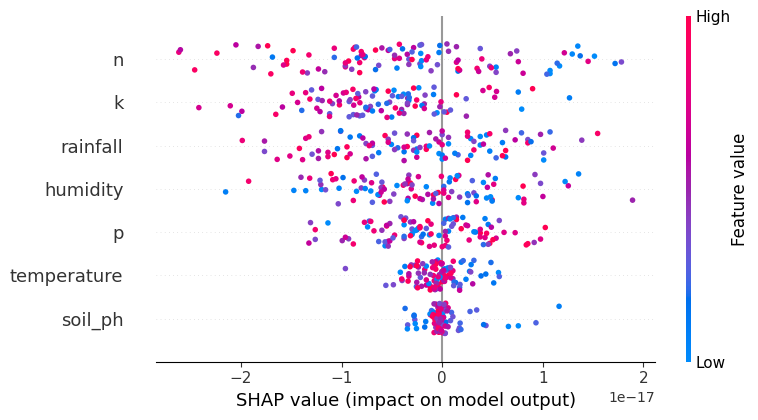

In [20]:
shap.summary_plot(shap_values_2d, X_sample)


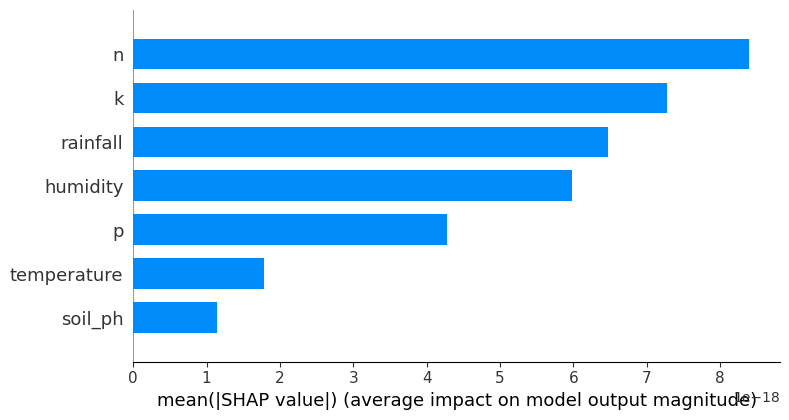

In [21]:
shap.summary_plot(shap_values_2d, X_sample, plot_type="bar")

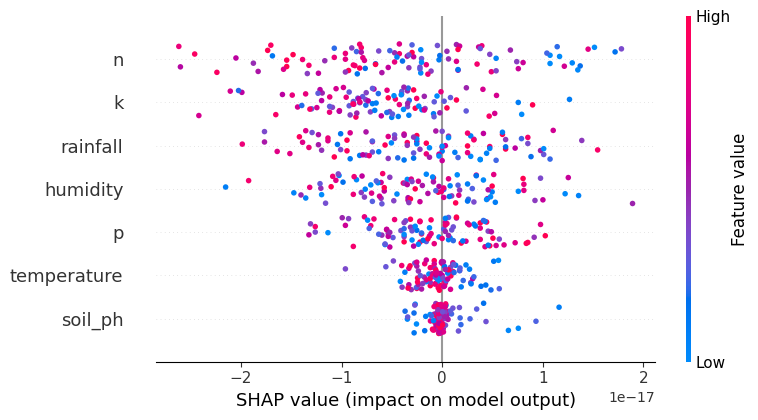

In [22]:
shap.summary_plot(shap_values_2d, X_sample)